# QueryVerse v0.0.1 — Text-to-SQL with a LoRA fine-tuned Llama-3.2-1B

Code for the paper **"QueryVerse: Transform Prompts into Data"** (Samuji Praneeth, Gundala Pallavi, Dr. R. Prasanna Kumar — Amrita Vishwa Vidyapeetham, Chennai).




**Runtime:** Colab → Runtime → Change runtime type → **A100** or **L4** GPU for the full run (a T4 works for quick mode).
Known limitations are listed in the repository README and addressed in **QueryVerse v0.0.2**.

## 1. Install dependencies

In [1]:
%%capture
!pip install unsloth
!pip install rouge nltk scikit-learn gradio

## 2. Configuration
- `RUN_MODE = "full"` uses the original configuration from the paper (100 epochs, 10,900 steps). Use an **A100** or **L4** runtime.
- `RUN_MODE = "quick"` trains for 60 steps to check the pipeline (~5 min). Inference then uses the model published with the paper.

The re-trained model is published to **new** repositories (`QueryVerse-v0.0.1`). The models referenced in the paper (`QueryVerse_final`, `QueryVerse_final_merged`) are left untouched.

Checkpoints are saved to Google Drive every 500 steps. If the session disconnects, re-run all cells and training resumes from the last checkpoint.

In [2]:
RUN_MODE    = "full"        # "full" or "quick"
PUSH_TO_HUB = True          # publish the re-trained model (needs HF_TOKEN in Colab secrets)
USE_DRIVE   = True          # keep checkpoints and results on Google Drive

HF_USERNAME = "EvaruRaMeeruAntha"
HF_ADAPTER  = f"{HF_USERNAME}/QueryVerse-v0.0.1"          # re-trained LoRA adapter
HF_MERGED   = f"{HF_USERNAME}/QueryVerse-v0.0.1-merged"   # re-trained merged model
PAPER_MERGED = f"{HF_USERNAME}/QueryVerse_final_merged"   # model published with the paper (not modified)

BASE_MODEL     = "unsloth/Llama-3.2-1B-Instruct"
MAX_SEQ_LENGTH = 2048
SEED           = 3407

import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/QueryVerse-v0.0.1"
else:
    WORK_DIR = "/content/QueryVerse-v0.0.1"

CHECKPOINT_DIR = f"{WORK_DIR}/checkpoints"
ADAPTER_DIR    = f"{WORK_DIR}/adapter"
RESULTS_DIR    = f"{WORK_DIR}/results"
MERGED_DIR     = "/content/QueryVerse-v0.0.1-merged"   # large; kept on the VM, published to the Hub
for d in (CHECKPOINT_DIR, ADAPTER_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok = True)

# Model used for inference, evaluation and the app
INFERENCE_MODEL = MERGED_DIR if RUN_MODE == "full" else PAPER_MERGED
print("Run mode:", RUN_MODE, "| work dir:", WORK_DIR, "| inference model:", INFERENCE_MODEL)

Mounted at /content/drive
Run mode: full | work dir: /content/drive/MyDrive/QueryVerse-v0.0.1 | inference model: /content/QueryVerse-v0.0.1-merged


## 3. Load the base model (4-bit)

In [3]:
from unsloth import FastLanguageModel, is_bfloat16_supported
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = BASE_MODEL,
    max_seq_length = MAX_SEQ_LENGTH,
    dtype = None,          # auto: float16 on T4/V100, bfloat16 on Ampere+
    load_in_4bit = True,   # 4-bit quantisation to reduce memory
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1111 13:44:34.239000 334 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 13:44:34.329000 334 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.3: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Will load unsloth/Llama-3.2-1B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.


## 4. Apply LoRA
LoRA adapters on the attention projections (`q/k/v/o_proj`), which control how tokens relate to each other, and on the MLP layers (`gate/up/down_proj`), which handle non-linear transformations.

In [4]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,                     # LoRA rank
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj"],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = SEED,
    use_rslora = False,
    loftq_config = None,
)

Unsloth 2026.11.3 patched 16 layers with 16 QKV layers, 16 O layers and 16 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).


## 5. Prepare the Spider dataset
Each (question, SQL) pair becomes a Llama-3.1 chat conversation: the question is the user turn and the SQL query is the assistant turn.

In [5]:
from unsloth.chat_templates import get_chat_template
from datasets import load_dataset

tokenizer = get_chat_template(tokenizer, chat_template = "llama-3.1")

def format_entries(entry):
    conversations = [
        [
            {"role": "user", "content": question},
            {"role": "assistant", "content": query},
        ]
        for question, query in zip(entry["question"], entry["query"])
    ]
    texts = [
        tokenizer.apply_chat_template(convo, tokenize = False, add_generation_prompt = False)
        for convo in conversations
    ]
    return {"text": texts}

ds = load_dataset("xlangai/spider", split = "train")
dataset = ds.map(format_entries, batched = True)
print(dataset)

Dataset({
    features: ['db_id', 'query', 'question', 'query_toks', 'query_toks_no_value', 'question_toks', 'text'],
    num_rows: 7000
})


In [6]:
print(dataset[5]["text"])

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

<|eot_id|><|start_header_id|>user<|end_header_id|>

What are the names of the heads who are born outside the California state?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

SELECT name FROM head WHERE born_state != 'California'<|eot_id|>


## 6. Trainer
Hyperparameters are the ones used for the published model. Only the precision flags are automatic (T4 has no bfloat16), and `quick` mode limits the number of steps.

In [7]:
import inspect
from trl import SFTTrainer, SFTConfig
from transformers import DataCollatorForSeq2Seq

full = RUN_MODE == "full"

# TRL renamed max_seq_length -> max_length in newer versions
_seq_key = "max_seq_length" if "max_seq_length" in inspect.signature(SFTConfig).parameters else "max_length"

args = SFTConfig(
    dataset_text_field = "text",
    packing = False,
    dataset_num_proc = 4,
    per_device_train_batch_size = 16,
    gradient_accumulation_steps = 4,          # effective batch size 64
    warmup_steps = 1000 if full else 5,
    num_train_epochs = 100,
    max_steps = -1 if full else 60,
    learning_rate = 1e-4,
    max_grad_norm = 1.0,
    fp16 = not is_bfloat16_supported(),
    bf16 = is_bfloat16_supported(),
    logging_steps = 50 if full else 5,
    optim = "adamw_8bit",
    weight_decay = 0.02,
    lr_scheduler_type = "cosine_with_restarts",
    seed = SEED,
    output_dir = CHECKPOINT_DIR,
    save_steps = 500,
    save_total_limit = 2,
    report_to = "none",
    **{_seq_key: MAX_SEQ_LENGTH},
)

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    data_collator = DataCollatorForSeq2Seq(tokenizer = tokenizer),
    args = args,
)

Unsloth: We found double BOS tokens - we shall remove one automatically.


In [8]:
# Compute the loss only on the assistant's SQL, not on the question
from unsloth.chat_templates import train_on_responses_only

trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|start_header_id|>user<|end_header_id|>\n\n",
    response_part = "<|start_header_id|>assistant<|end_header_id|>\n\n",
)

# Check: the decoded training targets should be SQL only
sample = trainer.train_dataset[5]
print(tokenizer.decode([t for t, l in zip(sample["input_ids"], sample["labels"]) if l != -100]))

Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


SELECT name FROM head WHERE born_state != 'California'<|eot_id|>


## 7. Train
Resumes automatically from the latest checkpoint on Drive if one exists (full mode only).

In [9]:
import glob, json

checkpoints = sorted(glob.glob(f"{CHECKPOINT_DIR}/checkpoint-*"), key = lambda p: int(p.rsplit("-", 1)[1]))
resume = checkpoints[-1] if (full and checkpoints) else None
print("Resuming from:", resume or "scratch")

trainer_stats = trainer.train(resume_from_checkpoint = resume)
print(f"Training time (this session): {trainer_stats.metrics['train_runtime'] / 60:.1f} min")

# Keep the full log so the loss curve survives a disconnect
with open(f"{RESULTS_DIR}/log_history.json", "w") as f:
    json.dump(trainer.state.log_history, f, indent = 1)

Resuming from: /content/drive/MyDrive/QueryVerse-v0.0.1/checkpoints/checkpoint-10500


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 7,000 | Num Epochs = 100 | Total steps = 11,000
O^O/ \_/ \    Batch size per device = 16 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (16 x 4 x 1) = 64
 "-____-"     Trainable parameters = 11,272,192 of 1,247,086,592 (0.90% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
10550,0.000217
10600,0.000201
10650,0.000253
10700,0.000190
10750,0.000266
10800,0.000173
10850,0.000236
10900,0.000201
10950,0.000207
11000,0.000210


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/QueryVerse-v0.0.1/checkpoints/checkpoint-11000/tokenizer_config.json.


Training time (this session): 27.7 min


## 8. Training loss curve

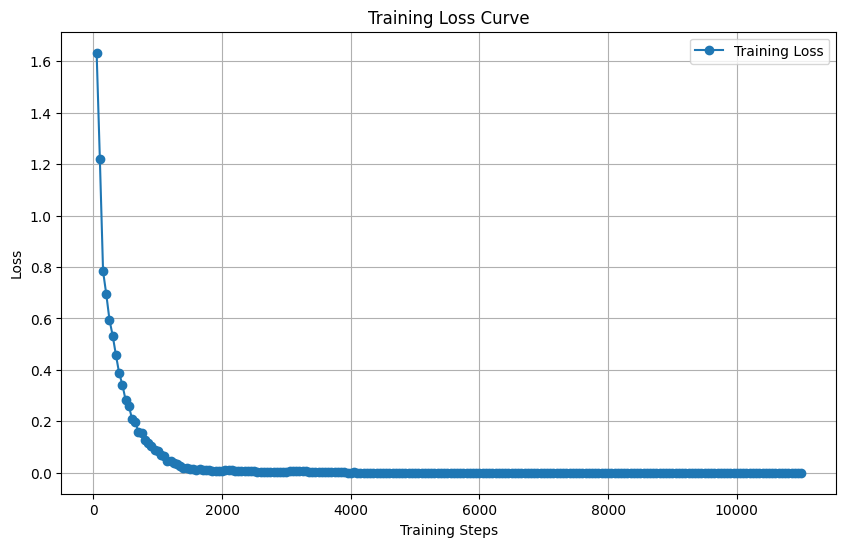

In [10]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history
steps = [l["step"] for l in logs if "loss" in l]
loss_values = [l["loss"] for l in logs if "loss" in l]

plt.figure(figsize = (10, 6))
plt.plot(steps, loss_values, label = "Training Loss", marker = "o")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid()
plt.savefig(f"{RESULTS_DIR}/training_loss.png", dpi = 150, bbox_inches = "tight")
plt.show()

## 9. Save the LoRA adapter and the merged model

In [11]:
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Adapter saved to", ADAPTER_DIR)

# Merge the adapter into the base model (16-bit) for standalone inference
model.save_pretrained_merged(MERGED_DIR, tokenizer, save_method = "merged_16bit")
print("Merged model saved to", MERGED_DIR)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/QueryVerse-v0.0.1/adapter/tokenizer_config.json.


Adapter saved to /content/drive/MyDrive/QueryVerse-v0.0.1/adapter


Unsloth: Restored added_tokens_decoder metadata in /content/QueryVerse-v0.0.1-merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:31<00:00, 31.98s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:40<00:00, 40.65s/it]


Unsloth: Merge process complete. Saved to `/content/QueryVerse-v0.0.1-merged`
Merged model saved to /content/QueryVerse-v0.0.1-merged


In [12]:
# Optional: download the adapter as a zip
DOWNLOAD_ADAPTER = False

if DOWNLOAD_ADAPTER:
    import shutil
    from google.colab import files
    shutil.make_archive(ADAPTER_DIR, "zip", ADAPTER_DIR)
    files.download(ADAPTER_DIR + ".zip")

## 10. Publish to Hugging Face (optional)
Add a **write** token in Colab → 🔑 Secrets as `HF_TOKEN`. Never paste tokens into a cell.

In [13]:
if PUSH_TO_HUB and RUN_MODE == "quick":
    print("Skipped: a 60-step quick-mode model should not be published.")
elif PUSH_TO_HUB:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
    model.push_to_hub(HF_ADAPTER, token = HF_TOKEN)
    tokenizer.push_to_hub(HF_ADAPTER, token = HF_TOKEN)
    model.push_to_hub_merged(HF_MERGED, tokenizer, save_method = "merged_16bit", token = HF_TOKEN)
    print(f"Published: https://huggingface.co/{HF_ADAPTER} and https://huggingface.co/{HF_MERGED}")
else:
    print("Skipped (PUSH_TO_HUB = False)")

Saved model to https://huggingface.co/EvaruRaMeeruAntha/QueryVerse-v0.0.1


Unsloth: Restored added_tokens_decoder metadata in /tmp/tmp7kq6gdc_/tokenizer_config.json.


Unsloth: Restored added_tokens_decoder metadata in EvaruRaMeeruAntha/QueryVerse-v0.0.1-merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:37<00:00, 37.36s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [01:28<00:00, 88.97s/it]


Unsloth: Merge process complete. Saved to `/content/EvaruRaMeeruAntha/QueryVerse-v0.0.1-merged`
Published: https://huggingface.co/EvaruRaMeeruAntha/QueryVerse-v0.0.1 and https://huggingface.co/EvaruRaMeeruAntha/QueryVerse-v0.0.1-merged


In [14]:
# Free GPU memory before inference
import gc
del trainer, model
gc.collect()
torch.cuda.empty_cache()

## 11. Inference
The prompt uses the same Llama-3.1 chat template as training. The schema and question go in the user turn. Decoding is greedy, and only the newly generated tokens are decoded.

In [15]:
import re

qv_model, qv_tokenizer = FastLanguageModel.from_pretrained(
    model_name = INFERENCE_MODEL,
    max_seq_length = MAX_SEQ_LENGTH,
    dtype = None,
    load_in_4bit = False,
)
qv_tokenizer = get_chat_template(qv_tokenizer, chat_template = "llama-3.1")
FastLanguageModel.for_inference(qv_model)


def clean_sql(text):
    """Strip markdown fences / prefixes and keep the first SQL statement."""
    text = text.strip()
    fence = re.search(r"```(?:sql)?\s*(.*?)(?:```|$)", text, re.IGNORECASE | re.DOTALL)
    if fence:
        text = fence.group(1)
    text = re.sub(r"^\s*(?:sql|sql query)\s*:\s*", "", text, flags = re.IGNORECASE)
    return text.split(";")[0].strip()


def build_user_message(question, schema = None):
    if schema and schema.strip():
        schema = "\n".join(line.strip() for line in schema.strip().splitlines() if line.strip())
        return f"Schema:\n{schema}\n\nQuestion: {question.strip()}"
    return question.strip()


def generate_sql(model, tokenizer, question, schema = None, max_new_tokens = 128):
    messages = [{"role": "user", "content": build_user_message(question, schema)}]
    inputs = tokenizer.apply_chat_template(
        messages, tokenize = True, add_generation_prompt = True,
        return_tensors = "pt", return_dict = True,
    ).to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens = max_new_tokens,
            do_sample = False,
            use_cache = True,
            pad_token_id = tokenizer.eos_token_id,
        )
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return clean_sql(tokenizer.decode(new_tokens, skip_special_tokens = True))


examples = [
    "How many heads of the departments are older than 56?",
    "What are the names of the heads who are born outside the California state?",
    "Show the name and the release year of the song by the youngest singer.",
]
for q in examples:
    print("Q:  ", q)
    print("SQL:", generate_sql(qv_model, qv_tokenizer, q), "\n")

==((====))==  Unsloth 2026.11.3: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Will load /content/QueryVerse-v0.0.1-merged as a legacy tokenizer.


Q:   How many heads of the departments are older than 56?


Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SQL: SELECT count(*) FROM department WHERE head_age  >  56 

Q:   What are the names of the heads who are born outside the California state?
SQL: SELECT name FROM head WHERE born_state != 'California' 

Q:   Show the name and the release year of the song by the youngest singer.
SQL: SELECT name ,  release_year FROM song ORDER BY age LIMIT 1 



In [16]:
db_schema = """
TABLE employees (
    id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary INT
);
TABLE departments (
    id INT PRIMARY KEY,
    name VARCHAR(50)
);
"""
question = "Get the names of employees who earn more than 50000."
print(generate_sql(qv_model, qv_tokenizer, question, db_schema))

Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SELECT name FROM employees WHERE salary  >  50000


## 12. Evaluation (as reported in the paper)
Compares QueryVerse with **Mistral-7B-Instruct** on the paper's example question using BLEU, ROUGE and TF-IDF cosine similarity. Both models get the same schema and question.

Note: this is a single-example, text-similarity evaluation, as in the paper. Its limitations, and the move to execution accuracy on the full Spider dev set, are covered in v0.0.2.

In [17]:
from nltk.translate.bleu_score import sentence_bleu
from rouge import Rouge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sql_schema = """
CREATE TABLE Employees (
    EmployeeID INT PRIMARY KEY,
    Name VARCHAR(100),
    Age INT,
    Department VARCHAR(50),
    Salary DECIMAL(10,2),
    JoiningDate DATE
);
CREATE TABLE Departments (
    DepartmentID INT PRIMARY KEY,
    DepartmentName VARCHAR(50),
    ManagerID INT
);
"""
sql_question = ("Write an SQL query to find the average salary of employees in each department, "
                "ordered from highest to lowest.")
expected_sql_output = """
SELECT Department, AVG(Salary) AS AvgSalary
FROM Employees
GROUP BY Department
ORDER BY AvgSalary DESC;
"""


def evaluate_response(model_name, generated_sql, expected_sql):
    generated_sql = generated_sql.strip() or "<empty>"
    expected_sql = expected_sql.strip()
    bleu = sentence_bleu([expected_sql.split()], generated_sql.split())
    rouge_scores = Rouge().get_scores(generated_sql, expected_sql)[0]
    vectors = TfidfVectorizer().fit_transform([generated_sql, expected_sql])
    cosine = cosine_similarity(vectors)[0, 1]

    print(f"\n=== {model_name} ===")
    print("Generated SQL:\n", generated_sql)
    print(f"BLEU: {bleu:.4f}")
    for k in ("rouge-1", "rouge-2", "rouge-l"):
        s = rouge_scores[k]
        print(f"{k.upper():8s} P={s['p']:.4f} R={s['r']:.4f} F1={s['f']:.4f}")
    print(f"Cosine similarity: {cosine:.4f}")
    return {"model": model_name, "sql": generated_sql, "bleu": bleu,
            "rouge-1": rouge_scores["rouge-1"]["f"], "rouge-2": rouge_scores["rouge-2"]["f"],
            "rouge-l": rouge_scores["rouge-l"]["f"], "cosine": cosine}


results = [evaluate_response("QueryVerse (fine-tuned Llama-3.2-1B)",
                             generate_sql(qv_model, qv_tokenizer, sql_question, sql_schema),
                             expected_sql_output)]

Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== QueryVerse (fine-tuned Llama-3.2-1B) ===
Generated SQL:
 SELECT department_id ,  AVG(salary) FROM Employees GROUP BY department_id ORDER BY AVG(salary) DESC
BLEU: 0.2213
ROUGE-1  P=0.6000 R=0.5000 F1=0.5455
ROUGE-2  P=0.3333 R=0.3077 F1=0.3200
ROUGE-L  P=0.6000 R=0.5000 F1=0.5455
Cosine similarity: 0.5041


In [18]:
# Baseline: Mistral-7B-Instruct (4-bit, ~4.5 GB download)
RUN_MISTRAL_COMPARISON = True

if RUN_MISTRAL_COMPARISON:
    mistral_model, mistral_tokenizer = FastLanguageModel.from_pretrained(
        model_name = "unsloth/mistral-7b-instruct-v0.3-bnb-4bit",
        max_seq_length = MAX_SEQ_LENGTH,
        dtype = None,
        load_in_4bit = True,
    )
    FastLanguageModel.for_inference(mistral_model)
    results.append(evaluate_response("Mistral-7B-Instruct",
                                     generate_sql(mistral_model, mistral_tokenizer, sql_question, sql_schema),
                                     expected_sql_output))
    del mistral_model
    gc.collect()
    torch.cuda.empty_cache()

==((====))==  Unsloth 2026.11.3: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== Mistral-7B-Instruct ===
Generated SQL:
 SELECT Department.DepartmentName, AVG(Employees.Salary) as AverageSalary
FROM Departments AS Department
JOIN Employees ON Department.DepartmentID = Employees.Department
GROUP BY Department.DepartmentName
ORDER BY AverageSalary DESC
BLEU: 0.0000
ROUGE-1  P=0.4000 R=0.6667 F1=0.5000
ROUGE-2  P=0.1154 R=0.2308 F1=0.1538
ROUGE-L  P=0.3500 R=0.5833 F1=0.4375
Cosine similarity: 0.6111


/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


In [19]:
import pandas as pd
summary = pd.DataFrame(results)
summary.to_csv(f"{RESULTS_DIR}/evaluation.csv", index = False)
summary.drop(columns = ["sql"]).round(4)

,model,bleu,rouge-1,rouge-2,rouge-l,cosine
0,QueryVerse (fine-tuned Llama-3.2-1B),0.2213,0.5455,0.3200,0.5455,0.5041
1,Mistral-7B-Instruct,0.0000,0.5000,0.1538,0.4375,0.6111


## 13. Gradio app

In [20]:
import gradio as gr

def app_generate(schema, question):
    if not question.strip():
        return "Please enter a question."
    return generate_sql(qv_model, qv_tokenizer, question, schema)

with gr.Blocks(title = "QueryVerse") as demo:
    gr.Markdown("## QueryVerse: Natural Language to SQL")
    with gr.Row():
        schema_input = gr.Textbox(
            label = "Database schema (optional)", lines = 10,
            placeholder = "Customers(CustomerID, FirstName, LastName, Email, CreatedAt)\nOrders(OrderID, CustomerID, OrderDate)",
        )
        question_input = gr.Textbox(
            label = "Question",
            placeholder = "Show all customers who placed an order in the last 30 days.",
        )
    generate_btn = gr.Button("Generate SQL", variant = "primary")
    output_sql = gr.Code(label = "Generated SQL", language = "sql")
    generate_btn.click(app_generate, inputs = [schema_input, question_input], outputs = output_sql)

demo.launch(share = True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c461d706484ab8ac5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
